In [85]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns 
from sklearn.model_selection import train_test_split
from sklearn.linear_model import Lasso
from sklearn.linear_model import Ridge
from sklearn.svm import LinearSVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,r2_score
from sklearn.preprocessing import StandardScaler

In [86]:
sns.set_theme(style="darkgrid")

plt.rcParams['figure.facecolor'] = '#1e1e1e'
plt.rcParams['axes.facecolor'] = '#1e1e1e'
plt.rcParams['axes.edgecolor'] = 'white'
plt.rcParams['axes.labelcolor'] = 'white'
plt.rcParams['text.color'] = 'white'
plt.rcParams['xtick.color'] = 'white'
plt.rcParams['ytick.color'] = 'white'

In [87]:
df_students=pd.read_csv(r"D:\Study\Data Science\enhanced_student_habits_performance_dataset.csv")
print(df_students.head())
print(df_students.info())
print(df_students.columns)
print(df_students.dtypes)
df_students.isnull().sum()


   student_id  age  gender             major  study_hours_per_day  \
0      100000   26    Male  Computer Science             7.645367   
1      100001   28    Male              Arts             5.700000   
2      100002   17    Male              Arts             2.400000   
3      100003   27   Other        Psychology             3.400000   
4      100004   25  Female          Business             4.700000   

   social_media_hours  netflix_hours part_time_job  attendance_percentage  \
0                 3.0            0.1           Yes                   70.3   
1                 0.5            0.4            No                   88.4   
2                 4.2            0.7            No                   82.1   
3                 4.6            2.3           Yes                   79.3   
4                 0.8            2.7           Yes                   62.9   

   sleep_hours  ... screen_time  study_environment access_to_tutoring  \
0          6.2  ...        10.9  Co-Learning Grou

student_id                       0
age                              0
gender                           0
major                            0
study_hours_per_day              0
social_media_hours               0
netflix_hours                    0
part_time_job                    0
attendance_percentage            0
sleep_hours                      0
diet_quality                     0
exercise_frequency               0
parental_education_level         0
internet_quality                 0
mental_health_rating             0
extracurricular_participation    0
previous_gpa                     0
semester                         0
stress_level                     0
dropout_risk                     0
social_activity                  0
screen_time                      0
study_environment                0
access_to_tutoring               0
family_income_range              0
parental_support_level           0
motivation_level                 0
exam_anxiety_score               0
learning_style      

In [88]:
Nameobj=['gender','major','part_time_job','diet_quality','parental_education_level','internet_quality','extracurricular_participation','dropout_risk','study_environment','access_to_tutoring','family_income_range','learning_style']
df_students_encode=pd.get_dummies(df_students,columns=Nameobj,drop_first=True)
print(df_students_encode.dtypes)

student_id                                 int64
age                                        int64
study_hours_per_day                      float64
social_media_hours                       float64
netflix_hours                            float64
attendance_percentage                    float64
sleep_hours                              float64
exercise_frequency                         int64
mental_health_rating                     float64
previous_gpa                             float64
semester                                   int64
stress_level                             float64
social_activity                            int64
screen_time                              float64
parental_support_level                     int64
motivation_level                           int64
exam_anxiety_score                         int64
time_management_score                    float64
exam_score                                 int64
gender_Male                                 bool
gender_Other        

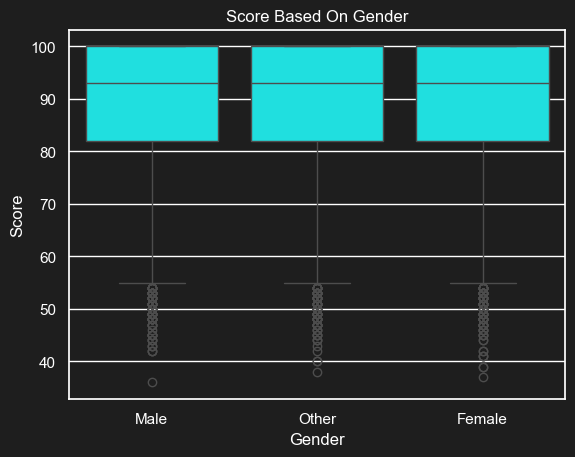

In [89]:
sns.boxplot(data = df_students , x = 'gender' , y = 'exam_score', color = 'cyan')
plt.xlabel('Gender')
plt.ylabel('Score')
plt.title('Score Based On Gender')
plt.show()

In [90]:
X=df_students_encode.drop('exam_score',axis=1)
x=X.drop('student_id',axis=1)
y=df_students_encode['exam_score']
x_train,x_test,y_train,y_test=train_test_split(x,y, test_size=0.2,random_state=42)

In [91]:
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train)  
x_test_scaled = scaler.transform(x_test)

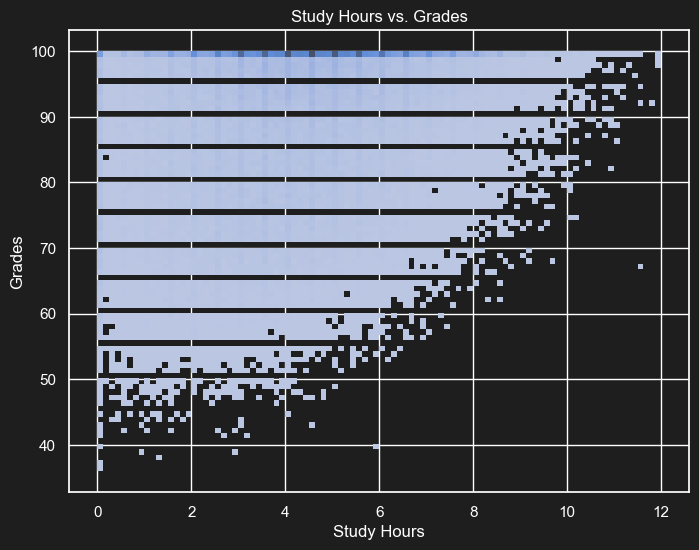

In [92]:
plt.figure(figsize=(8, 6))
sns.histplot(x='study_hours_per_day', y='exam_score', data=df_students_encode)
plt.title('Study Hours vs. Grades')
plt.xlabel('Study Hours')
plt.ylabel('Grades')
plt.show()

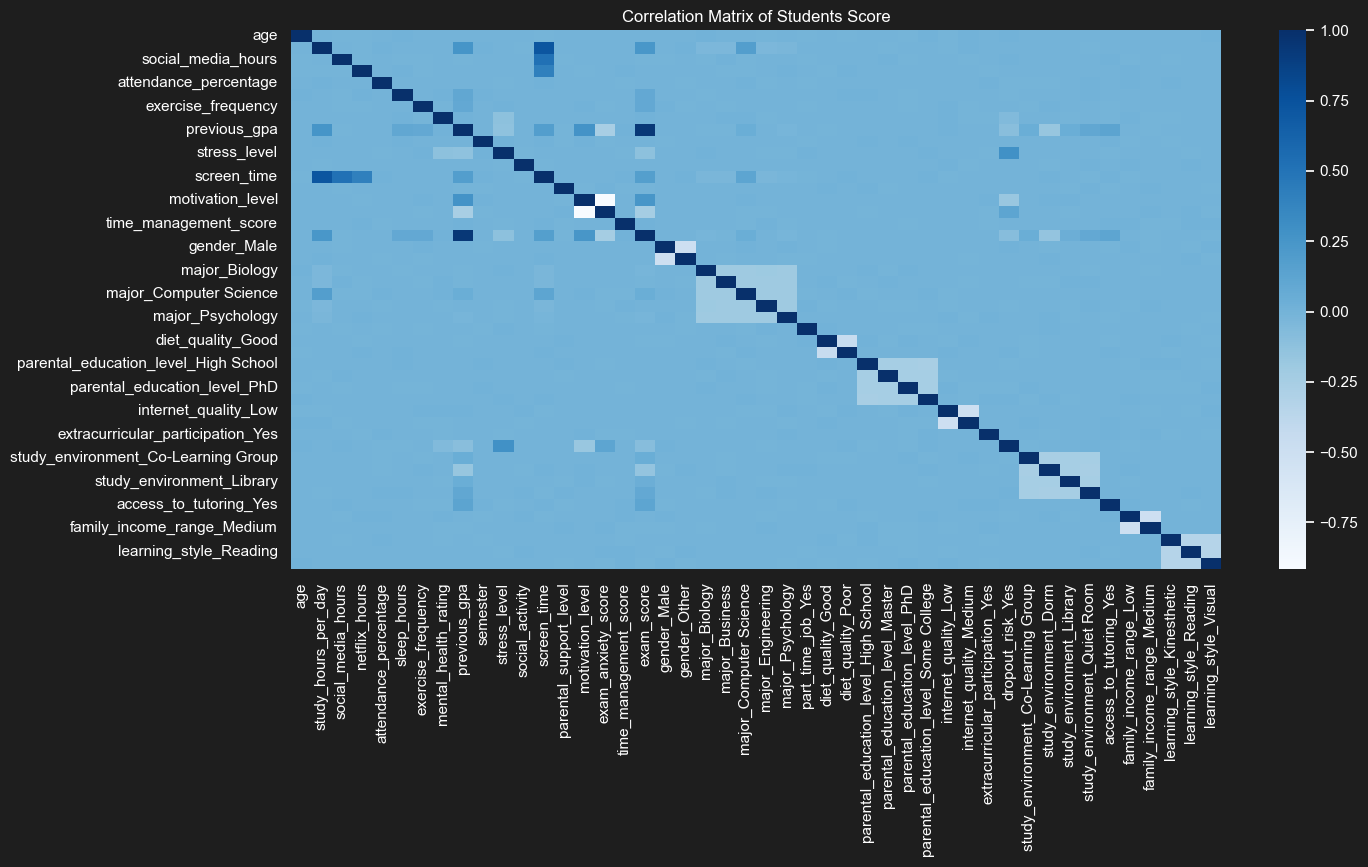

In [93]:
plt.figure(figsize=(15, 7))
correlation_matrix = df_students_encode.drop('student_id', axis=1).corr(numeric_only=True)
sns.heatmap(correlation_matrix, cmap='Blues')
plt.title('Correlation Matrix of Students Score')
plt.show()

In [94]:
linear = LinearRegression()
linear.fit(x_train_scaled,y_train)
y_pred=linear.predict(x_test_scaled)
mse_linear=mean_squared_error(y_test,y_pred)
r2_linear=r2_score(y_test,y_pred)
print(f"Mean Square Error : {mse_linear}")
print(f'R-Squared : {r2_linear}')

Mean Square Error : 17.549185499547793
R-Squared : 0.8703789533840951


In [95]:

lasso = Lasso(alpha=0.1, random_state=42)
lasso.fit(x_train_scaled, y_train)
y_pred = lasso.predict(x_test_scaled)
mse_lasso=mean_squared_error(y_test,y_pred)
r2_lasso=r2_score(y_test,y_pred)
print(f"Mean Square Error : {mse_lasso}")
print(f'R-Squared : {r2_lasso}')



Mean Square Error : 17.55247857613826
R-Squared : 0.8703546302020162


In [96]:
Ridge =Ridge(alpha=0.1, random_state=42)
Ridge.fit(x_train_scaled, y_train)
y_pred = Ridge.predict(x_test_scaled)
mse_ridge=mean_squared_error(y_test,y_pred)
r2_ridge=r2_score(y_test,y_pred)
print(f"Mean Square Error : {mse_ridge}")
print(f'R-Squared : {r2_ridge}')

Mean Square Error : 17.549186818487215
R-Squared : 0.8703789436422009


In [97]:
tree = DecisionTreeRegressor()
tree.fit(x_train_scaled,y_train)
y_pred=tree.predict(x_test_scaled)
mse_tree=mean_squared_error(y_test,y_pred)
r2_tree=r2_score(y_test,y_pred)
print(f"Mean Square Error : {mse_tree}")
print(f'R-Squared : {r2_tree}')


Mean Square Error : 36.8708125
R-Squared : 0.7276663748324992


In [98]:

svr = LinearSVR(C=1.0, epsilon=0.1, random_state=42, max_iter=10000)
svr.fit(x_train_scaled,y_train)
y_pred=svr.predict(x_test_scaled)
mse_svr=mean_squared_error(y_test,y_pred)
r2_svr=r2_score(y_test,y_pred)
print(f"Mean Square Error : {mse_svr}")
print(f'R-Squared : {r2_svr}')

Mean Square Error : 18.736769793155233
R-Squared : 0.8616072688471704


In [99]:
knn = KNeighborsRegressor()
knn.fit(x_train_scaled,y_train)
y_pred=knn.predict(x_test_scaled)
mse_knn=mean_squared_error(y_test,y_pred)
r2_knn=r2_score(y_test,y_pred)
print(f"Mean Square Error : {mse_knn}")
print(f'R-Squared : {r2_knn}')

Mean Square Error : 62.82062
R-Squared : 0.5359970117319762


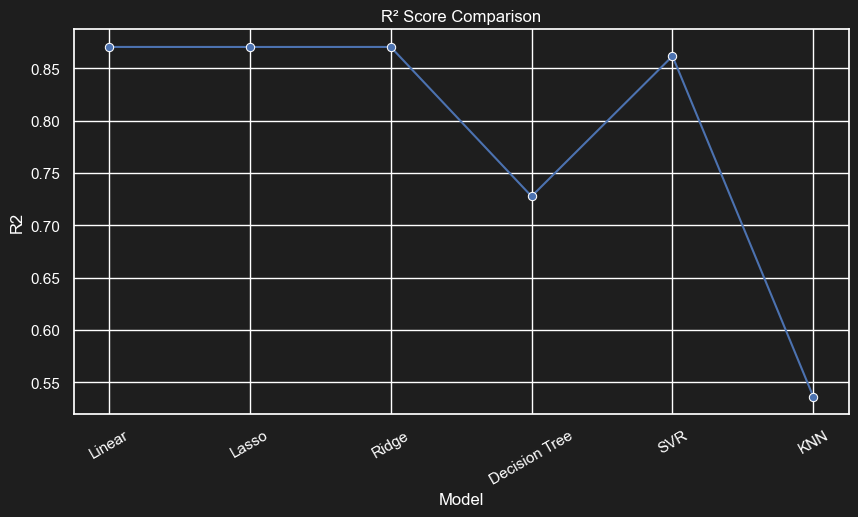

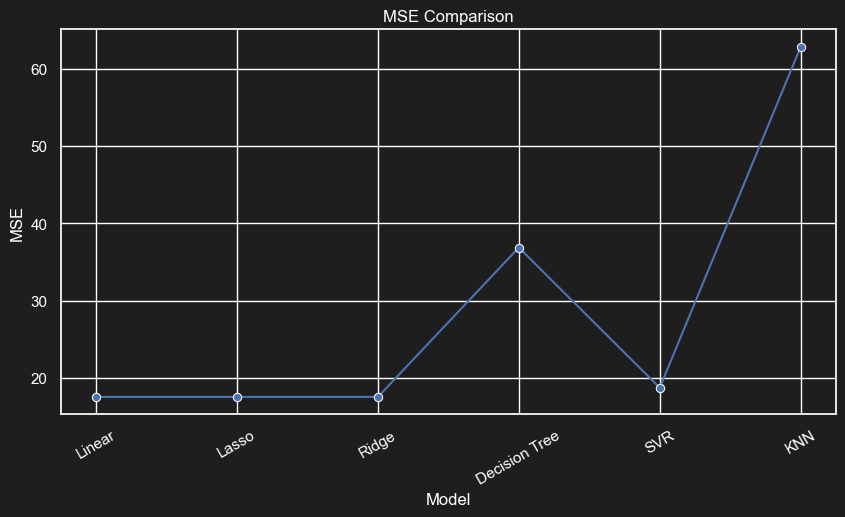

In [102]:
models = ['Linear', 'Lasso', 'Ridge', 'Decision Tree', 'SVR', 'KNN']

mse_values = [
    mse_linear,
    mse_lasso,
    mse_ridge,
    mse_tree,
    mse_svr,
    mse_knn
]

r2_values = [
    r2_linear,
    r2_lasso,
    r2_ridge,
    r2_tree,
    r2_svr,
    r2_knn
]

results = pd.DataFrame({
    'Model': models,
    'MSE': mse_values,
    'R2': r2_values
})

plt.figure(figsize=(10, 5))
sns.lineplot(data=results, x='Model', y='R2', marker='o')
plt.xticks(rotation=30)
plt.title('R² Score Comparison')
plt.show()



plt.figure(figsize=(10, 5))
sns.lineplot(data=results, x='Model', y='MSE', marker='o')
plt.xticks(rotation=30)
plt.title('MSE Comparison')
plt.show()